In [39]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import confusion_matrix,accuracy_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers,models
from tensorflow.keras.optimizers import Adam

In [40]:
data = pd.read_csv('ecg.csv',header=None)
data.dropna(inplace=True)

X = data.iloc[:,:-1].values
y = data.iloc[:,-1].values
y = (y==1).astype(int)

In [41]:
x_train,x_test,y_train,y_test = train_test_split(X,y,test_size=0.2,stratify= y,random_state=42)
x_train = x_train[y_train==0]

In [42]:
#normalize
scaler = MinMaxScaler()
x_train_s = scaler.fit_transform(x_train)
x_test_s = scaler.transform(x_test)
print("Train data shape",x_train_s.shape)
print("Test data shape",x_test_s.shape)

Train data shape (1663, 140)
Test data shape (1000, 140)


In [43]:
x_train_s

array([[0.6613297 , 0.66337694, 0.41180716, ..., 0.30660896, 0.27063566,
        0.21386368],
       [0.60332152, 0.56019831, 0.30860369, ..., 0.4258181 , 0.48534585,
        0.47478667],
       [0.72820198, 0.78941261, 0.60571631, ..., 0.19214185, 0.27029463,
        0.28108414],
       ...,
       [0.55187184, 0.55596891, 0.33620925, ..., 0.16343334, 0.25258265,
        0.25980555],
       [0.73151888, 0.71270954, 0.41697347, ..., 0.77539285, 0.67690639,
        0.49965873],
       [0.64637363, 0.60257972, 0.31462603, ..., 0.76145392, 0.69972455,
        0.51221649]], shape=(1663, 140))

In [44]:
input_dim = x_train_s.shape[1]
autoencoder = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu'),

    layers.Dense(16, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(input_dim,activation='sigmoid')
]) 

In [45]:
autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mse'])
autoencoder.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_32 (Dense)                     │ (None, 64)                  │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_33 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_34 (Dense)                     │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_35 (Dense)                     │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_36 (Dense)                     │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_37 (Dense)                     │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_38 (Dense)                     │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_39 (Dense)                     │ (None, 140)                 │           9,100 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,668 (92.45 KB)

 Trainable params: 23,668 (92.45 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:
history = autoencoder.fit(x_train_s,x_train_s,epochs=20,batch_size=512,
                    validation_split=0.2,verbose=1)

Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 223ms/step - loss: 0.0330 - mse: 0.0330 - val_loss: 0.0322 - val_mse: 0.0322
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 0.0314 - mse: 0.0314 - val_loss: 0.0300 - val_mse: 0.0300
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - loss: 0.0290 - mse: 0.0290 - val_loss: 0.0270 - val_mse: 0.0270
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - loss: 0.0260 - mse: 0.0260 - val_loss: 0.0234 - val_mse: 0.0234
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - loss: 0.0225 - mse: 0.0225 - val_loss: 0.0199 - val_mse: 0.0199
Epoch 6/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - loss: 0.0193 - mse: 0.0193 - val_loss: 0.0173 - val_mse: 0.0173
Epoch 7/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - loss: 0.0170 - mse: 0.0170 - val_loss: 0.0149 - val_mse: 0.0149
Epoch 8/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - loss: 0.0147 - mse: 0.0147 - val_loss: 0.0127 - val_mse: 0.0127
Epoch 9/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - loss: 0.0127 - mse: 0.0127

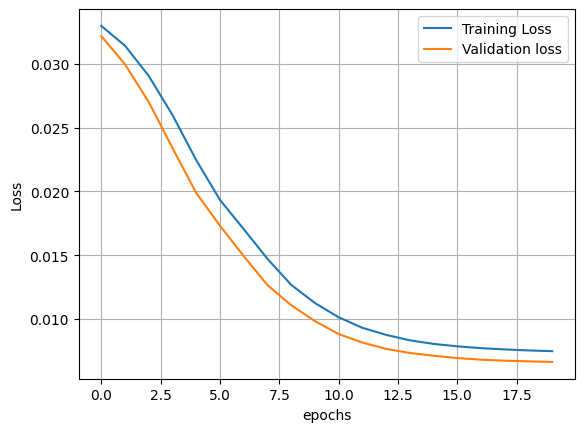

In [47]:
plt.plot(history.history['loss'],label="Training Loss")
plt.plot(history.history['val_loss'],label="Validation loss")
plt.xlabel("epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Reconstruction Threshold:  0.016398039751660837
Accuracy:  0.88
Confusion Matrix :
 [[362  54]
 [ 66 518]]


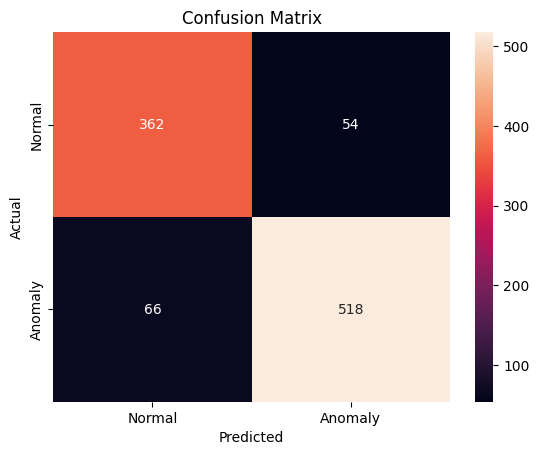

In [48]:
#Reconstruction error
recon_train = autoencoder.predict(x_train_s)
recon_test = autoencoder.predict(x_test_s)
train_err = np.mean(np.square(x_train_s - recon_train),axis = 1)
test_err = np.mean(np.square(x_test_s - recon_test),axis = 1)

threshold = np.mean(train_err) + np.std(train_err)

y_pred = [1 if e>threshold else 0 for e in test_err]
acc = accuracy_score(y_test,y_pred)

cm = confusion_matrix(y_test,y_pred)

print("Reconstruction Threshold: ",threshold)
print("Accuracy: ",acc)

print("Confusion Matrix :\n",cm)
sns.heatmap(cm, annot=True, fmt="d",xticklabels=["Normal", "Anomaly"],
    yticklabels=["Normal", "Anomaly"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()